# Real Estate Market in Kazakhstan: Analysis of Krisha.kz Listings

**Goal:** collect apartment sale listings from Krisha.kz and answer practical questions for buyers and investors: how asking prices are distributed, which districts are expensive or cheap per m², how rooms, floor and building type affect price, and how well a simple model can predict a price from listing features.

**What this notebook does**
1. Collects listings (web scraping with `requests` + `BeautifulSoup`), or loads a saved CSV.
2. Cleans the data with a documented pipeline and a data-quality report.
3. Explores prices by city, district, rooms, floor, building type and year.
4. Tests one hypothesis with statistics (is the first/last floor cheaper?).
5. Trains and compares regression models (`scikit-learn`) to predict price.
6. Generates a findings summary directly from the data.

**Important limitations** (details at the end): these are *asking* prices from a single snapshot in time, not transaction prices.

**Responsible scraping:** check the site's `robots.txt` and terms of use, keep the request rate low (the code waits between requests) and do not publish the raw scraped dataset; this repository only contains code.

## 1. Setup and configuration

In [1]:
import os, re, time, random
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
os.makedirs("images", exist_ok=True)

SCRAPE = True
CATEGORY_URL = "https://krisha.kz/prodazha/kvartiry/"
PAGES = 100
DELAY = (1.5, 3.0)
RAW_PATH = "krisha_raw.csv"
CITY = None
APARTMENTS_ONLY = True
MIN_N = 20
RANDOM_STATE = 42

## 2. Data collection

Each listing card is parsed into **raw text fields** (title, price, location, parameters, link). Parsing of numbers happens later in the cleaning step, so the raw data stays untouched and the cleaning is reproducible.

If you already have a CSV from a previous scraping run, set `SCRAPE = False`: the notebook accepts the older column names (`Price`, `Additional Parameters`) too.

In [2]:
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120 Safari/537.36",
    "Accept-Language": "ru-RU,ru;q=0.9,en;q=0.8",
}

def fetch_html(session, url, retries=3):
    """GET with retries and growing pauses. Returns HTML text or None."""
    for attempt in range(retries):
        try:
            r = session.get(url, headers=HEADERS, timeout=20)
            if r.status_code == 200:
                return r.text
            print(f"  HTTP {r.status_code} for {url} (attempt {attempt + 1})")
        except requests.RequestException as e:
            print(f"  Request error: {e} (attempt {attempt + 1})")
        time.sleep(2 * (attempt + 1))
    return None

def parse_card(card, page):
    """Extract raw text fields from one listing card."""
    def text(tag):
        return tag.get_text(" ", strip=True) if tag else ""
    title = card.find("a", class_="a-card__title")
    return {
        "Title": text(title),
        "PriceText": text(card.find("div", class_="a-card__price")),
        "Location": text(card.find("div", class_="a-card__subtitle")),
        "Params": text(card.find("div", class_="a-card__text-preview")),
        "Link": title.get("href", "") if title else "",
        "Page": page,
    }

def scrape_category(base_url, pages, delay):
    session = requests.Session()
    rows = []
    for page in range(1, pages + 1):
        html = fetch_html(session, f"{base_url}?page={page}")
        if html is None:
            print(f"Page {page}: could not be loaded, skipped")
            continue
        soup = BeautifulSoup(html, "html.parser")
        cards = soup.find_all("div", class_="a-card__inc")
        if not cards:
            print(f"Page {page}: no listing cards found. The site layout may have changed or the request was blocked: "
                  "open the page, use 'Inspect' and update the CSS classes in parse_card().")
            if page == 1:
                break
            continue
        rows.extend(parse_card(c, page) for c in cards)
        if page % 10 == 0:
            print(f"Page {page}/{pages} done, {len(rows)} listings so far")
        time.sleep(random.uniform(*delay))
    df = pd.DataFrame(rows)
    if not df.empty:
        df["ScrapedAt"] = date.today().isoformat()
    return df

In [3]:
if SCRAPE:
    raw = scrape_category(CATEGORY_URL, PAGES, DELAY)
    if raw.empty:
        raise RuntimeError("Nothing was scraped. See the messages above, or set SCRAPE = False and upload a CSV.")
    raw.to_csv(RAW_PATH, index=False)
    print(f"Saved {len(raw)} raw listings to {RAW_PATH}")
else:
    if not os.path.exists(RAW_PATH):
        try:
            from google.colab import files          # Colab: upload the CSV
            uploaded = files.upload()
            RAW_PATH = next(iter(uploaded))
        except ImportError:
            raise FileNotFoundError(f"{RAW_PATH} not found")
    raw = pd.read_csv(RAW_PATH)

# accept column names from the older scraper
raw = raw.rename(columns={"Price": "PriceText", "Additional Parameters": "Params"})
for col in ["Title", "PriceText", "Location", "Params"]:
    raw[col] = raw[col].fillna("").astype(str).replace({"N/A": ""})

print(raw.shape)
raw.head()

Page 10/100 done, 203 listings so far
Page 20/100 done, 403 listings so far
Page 30/100 done, 603 listings so far
Page 40/100 done, 803 listings so far
Page 50/100 done, 1003 listings so far
Page 60/100 done, 1203 listings so far
Page 70/100 done, 1403 listings so far
Page 80/100 done, 1603 listings so far
Page 90/100 done, 1803 listings so far
Page 100/100 done, 2003 listings so far
Saved 2003 raw listings to krisha_raw.csv
(2003, 7)


,Title,PriceText,Location,Params,Link,Page,ScrapedAt
0,2-комнатная квартира · 55 м² · 3/6 этаж,51 000 000 ₸,"Алатауский р-н, мкр Гажайып","жил. комплекс Arena City. Sport, монолитный до...",/a/show/1016684142,1,2026-11-19
1,2-комнатная квартира · 53.14 м² · 10/10 этаж,42 000 000 ₸,"Есильский р-н, Бокейхана 25Г — Пересечение Фар...","В залоге , жил. комплекс Apple City, монолитны...",/a/show/1016623701,1,2026-11-19
2,2-комнатная квартира · 47 м² · 9/12 этаж,34 500 000 ₸,"Алатауский р-н, мкр Акбулак, Момышулы 100","жил. комплекс Altyn Ai, монолитный дом, 2025 г...",/a/show/1015199379,1,2026-11-19
3,3-комнатная квартира · 72 м² · 5/12 этаж,33 400 000 ₸,Караменде би Шакаулы 9/1,"жил. комплекс Баспана Коктал, монолитный дом, ...",/a/show/698717298,1,2026-11-19
4,3-комнатная квартира · 56.6 м² · 4/5 этаж,55 800 000 ₸,"Бостандыкский р-н, мкр Казахфильм","панельный дом, 1976 г.п., состояние: свежий ре...",/a/show/1015926518,1,2026-11-19


## 3. Data cleaning

The cleaning rules are explicit and every step reports how many rows it removes:

- **Duplicates** are identified by the listing link (the same ad appears on several pages when new ads shift the pagination).
- Listings with a **missing price or area** are dropped; missing rooms, floor or year are **kept as missing** (not filled with made-up values).
- Prices like **"from X ₸"** belong to new-building complexes (a minimum price, not a specific apartment) and are excluded.
- **Implausible values** are removed with fixed bounds and an outlier rule on price per m² within each city (log scale, 3×IQR).

In [20]:
def parse_price(text):
    """Returns (price, is_from). 'is_from' marks 'from X' prices of new-building complexes."""
    t = str(text).strip().lower()
    m = re.search(r"\d[\d\s\u00a0]*", t)
    price = float(re.sub(r"\D", "", m.group())) if m else np.nan
    return price, t.startswith("от")

def parse_area(text):
    m = re.search(r"(\d+(?:[.,]\d+)?)\s*м²", text)
    return float(m.group(1).replace(",", ".")) if m else np.nan

def parse_rooms(text):
    m = re.search(r"(\d+)\s*-?\s*комн", text)
    return int(m.group(1)) if m else np.nan

def parse_floor(text):
    """Returns (floor, floors_total) from strings like '5/9 этаж' or '5 этаж'."""
    m = re.search(r"(\d+)\s*/\s*(\d+)\s*этаж", text)
    if m:
        return int(m.group(1)), int(m.group(2))
    m = re.search(r"(\d+)\s*этаж", text)
    return (int(m.group(1)), np.nan) if m else (np.nan, np.nan)

def parse_year(text):
    m = re.search(r"(\d{4})\s*г\.?\s*п", text)
    return int(m.group(1)) if m else np.nan

def parse_building_type(text):
    t = text.lower()
    for key, name in [("монолит", "monolithic"), ("кирпич", "brick"), ("панел", "panel"), ("каркас", "frame")]:
        if key in t:
            return name
    return np.nan

def parse_location(text):
    """'Алматы, Бостандыкский р-н, ...' -> ('Алматы', 'Бостандыкский')"""
    parts = [p.strip() for p in str(text).split(",") if p.strip()]
    city = parts[0] if parts else np.nan
    district = np.nan
    for p in parts[1:]:
        m = re.match(r"^([А-Яа-яЁё\- ]+?)\s*(?:р-н|район)\b", p)
        if m:
            district = m.group(1).strip()
            break
    return city, district

def parse_property_type(title):
    t = title.lower()
    if "квартир" in t:
        return "apartment"
    if "дом" in t or "дач" in t:
        return "house"
    return "other"

In [22]:
def clean_listings(raw):
    steps = []
    df = raw.copy()
    steps.append(("Raw rows", len(df)))

    # 1. duplicates
    if "Link" in df.columns and df["Link"].fillna("").astype(str).str.len().gt(0).any():
        key = ["Link"]
    else:
        key = ["Title", "PriceText", "Location", "Params"]
    df = df.drop_duplicates(subset=key)
    steps.append(("After removing duplicate listings", len(df)))

    # 2. parse fields from raw text
    pp = df["PriceText"].apply(parse_price)
    df["price"] = [p[0] for p in pp]
    df["price_is_from"] = [p[1] for p in pp]
    text = df["Title"] + " " + df["Params"]
    df["area"] = df["Title"].apply(parse_area)
    df["rooms"] = df["Title"].apply(parse_rooms)
    fl = text.apply(parse_floor)
    df["floor"] = [f[0] for f in fl]
    df["floors_total"] = [f[1] for f in fl]
    df["year_built"] = text.apply(parse_year)
    df["building_type"] = text.apply(parse_building_type)
    loc = df["Location"].apply(parse_location)
    df["city"] = [l[0] for l in loc]
    df["district"] = [l[1] for l in loc]
    df["property_type"] = df["Title"].apply(parse_property_type)

    # 3. core fields
    df = df.dropna(subset=["price", "area", "city"])
    steps.append(("After dropping rows without price, area or city", len(df)))

    df = df[~df["price_is_from"]]
    steps.append(("After removing 'from X' prices (new-building complexes)", len(df)))

    if APARTMENTS_ONLY:
        df = df[df["property_type"] == "apartment"]
        steps.append(("After keeping apartments only", len(df)))

    # 4. plausibility bounds
    df = df[df["price"].between(1e6, 2e9) & df["area"].between(10, 500)]
    steps.append(("After plausibility bounds (price 1M-2B tenge, area 10-500 m2)", len(df)))

    df = df.copy()
    df["price_per_m2"] = df["price"] / df["area"]

    # 5. outliers of price per m2 within each city (log scale, 3 x IQR)
    lp = np.log(df["price_per_m2"])
    q1 = lp.groupby(df["city"]).transform(lambda s: s.quantile(0.25))
    q3 = lp.groupby(df["city"]).transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    df = df[(lp >= q1 - 3 * iqr) & (lp <= q3 + 3 * iqr)].copy()
    steps.append(("After removing price-per-m2 outliers (3 x IQR, per city)", len(df)))

    # 6. consistency checks: set impossible values to missing instead of dropping the row
    df.loc[~df["rooms"].between(1, 10), "rooms"] = np.nan
    df.loc[df["floor"] > df["floors_total"], ["floor", "floors_total"]] = np.nan
    df.loc[~df["year_built"].between(1900, date.today().year + 3), "year_built"] = np.nan

    # floor category: first / middle / last
    fc = pd.Series(np.nan, index=df.index, dtype=object)
    known = df["floor"].notna() & df["floors_total"].notna()
    fc[known & (df["floor"] == 1)] = "first"
    fc[known & (df["floor"] == df["floors_total"]) & (df["floors_total"] > 1)] = "last"
    fc[known & (df["floor"] > 1) & (df["floor"] < df["floors_total"])] = "middle"
    df["floor_cat"] = fc

    report = pd.DataFrame(steps, columns=["step", "rows"])
    report["removed"] = -report["rows"].diff().fillna(0).astype(int)
    return df.reset_index(drop=True), report

df, cleaning_report = clean_listings(raw)
cleaning_report

,step,rows,removed
0,Raw rows,2003,0
1,After removing duplicate listings,1805,198
2,"After dropping rows without price, area or city",1805,0
3,After removing 'from X' prices (new-building complexes),1401,404
4,After keeping apartments only,1401,0
5,"After plausibility bounds (price 1M-2B tenge, area 10-500 m2)",1401,0
6,"After removing price-per-m2 outliers (3 x IQR, per city)",1394,7


In [23]:
DISTRICT_TO_CITY = {
    **{d: "Алматы" for d in ["Алатауский", "Алмалинский", "Ауэзовский", "Бостандыкский",
                             "Жетысуский", "Медеуский", "Наурызбайский", "Турксибский"]},
    **{d: "Астана" for d in ["Алматы", "Байконур", "Есильский", "Сарыарка", "Нура", "Сарайшык"]},
}

def parse_district(location):
    """District from a Location like 'Нура р-н, Е 908 — landmark'. NaN if the ad has no district."""
    head = str(location).split("—")[0]
    for part in head.split(",")[:2]:
        m = re.match(r"^\s*([А-Яа-яЁё\- ]+?)\s*(?:р-н|район)\b", part)
        if m:
            return m.group(1).strip()
    return np.nan

def infer_city(district):
    if isinstance(district, str):
        return DISTRICT_TO_CITY.get(district, "Other city")
    return "Unknown"

def parse_condition(text):
    m = re.search(r"состояние:\s*([^,]+)", text, flags=re.I)
    return m.group(1).strip().lower() if m else np.nan

def clean_listings(raw):
    steps = []
    df = raw.copy()
    steps.append(("Raw rows", len(df)))

    # 1. duplicates (by listing link)
    key = ["Link"] if "Link" in df.columns else ["Title", "PriceText", "Location", "Params"]
    df = df.drop_duplicates(subset=key)
    steps.append(("After removing duplicate listings", len(df)))

    # 2. parse fields from raw text
    pp = df["PriceText"].apply(parse_price)
    df["price"] = [p[0] for p in pp]
    df["price_is_from"] = [p[1] for p in pp]
    text = df["Title"] + " " + df["Params"]
    df["area"] = df["Title"].apply(parse_area)
    df["rooms"] = df["Title"].apply(parse_rooms)
    fl = text.apply(parse_floor)
    df["floor"] = [f[0] for f in fl]
    df["floors_total"] = [f[1] for f in fl]
    df["year_built"] = text.apply(parse_year)
    df["building_type"] = text.apply(parse_building_type)
    df["district"] = df["Location"].apply(parse_district)
    df["city"] = df["district"].apply(infer_city)          # 'Unknown' when the ad has no district
    df["condition"] = df["Params"].apply(parse_condition)
    df["in_complex"] = np.where(df["Params"].str.contains("жил. комплекс", case=False, regex=False), "yes", "no")
    df["property_type"] = df["Title"].apply(parse_property_type)

    # 3. core fields, 'from X' prices (new-building complexes), apartments only
    df = df.dropna(subset=["price", "area"])
    steps.append(("After dropping rows without price or area", len(df)))
    df = df[~df["price_is_from"]]
    steps.append(("After removing 'from X' prices (new-building complexes)", len(df)))
    if APARTMENTS_ONLY:
        df = df[df["property_type"] == "apartment"]
        steps.append(("After keeping apartments only", len(df)))

    # 4. plausibility bounds
    df = df[df["price"].between(1e6, 2e9) & df["area"].between(10, 500)]
    steps.append(("After plausibility bounds (price 1M-2B tenge, area 10-500 m2)", len(df)))
    df = df.copy()
    df["price_per_m2"] = df["price"] / df["area"]

    # 5. outliers of price per m2 within each city (log scale, 3 x IQR)
    lp = np.log(df["price_per_m2"])
    q1 = lp.groupby(df["city"]).transform(lambda s: s.quantile(0.25))
    q3 = lp.groupby(df["city"]).transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    df = df[(lp >= q1 - 3 * iqr) & (lp <= q3 + 3 * iqr)].copy()
    steps.append(("After removing price-per-m2 outliers (3 x IQR, per city)", len(df)))

    # 6. impossible values become missing instead of dropping the row
    df.loc[~df["rooms"].between(1, 10), "rooms"] = np.nan
    df.loc[df["floor"] > df["floors_total"], ["floor", "floors_total"]] = np.nan
    df.loc[~df["year_built"].between(1900, date.today().year + 3), "year_built"] = np.nan

    fc = pd.Series(np.nan, index=df.index, dtype=object)
    known = df["floor"].notna() & df["floors_total"].notna()
    fc[known & (df["floor"] == 1)] = "first"
    fc[known & (df["floor"] == df["floors_total"]) & (df["floors_total"] > 1)] = "last"
    fc[known & (df["floor"] > 1) & (df["floor"] < df["floors_total"])] = "middle"
    df["floor_cat"] = fc

    report = pd.DataFrame(steps, columns=["step", "rows"])
    report["removed"] = -report["rows"].diff().fillna(0).astype(int)
    return df.reset_index(drop=True), report

df, cleaning_report = clean_listings(raw)
display(cleaning_report)

# choose the city to analyse: the largest city that could be identified
city_counts = df["city"].value_counts()
display(city_counts.rename("listings").to_frame())
known_cities = city_counts.drop(labels=["Unknown", "Other city"], errors="ignore")
CITY = known_cities.index[0]
print(f"Analysed city: {CITY}  |  city identified for {df['city'].isin(known_cities.index).mean()*100:.0f}% of listings")

,step,rows,removed
0,Raw rows,2003,0
1,After removing duplicate listings,1805,198
2,After dropping rows without price or area,1805,0
3,After removing 'from X' prices (new-building complexes),1401,404
4,After keeping apartments only,1401,0
5,"After plausibility bounds (price 1M-2B tenge, area 10-500 m2)",1401,0
6,"After removing price-per-m2 outliers (3 x IQR, per city)",1401,0


,listings
city,
Алматы,616
Астана,488
Unknown,246
Other city,51


Analysed city: Алматы  |  city identified for 79% of listings


In [25]:
pd.set_option("display.max_colwidth", 120)
print(raw[["Title", "Location", "Params"]].sample(8, random_state=1).to_string())
print()
print("Share of cleaned rows where each field was parsed, %:")
print(df[["area", "rooms", "floor", "floors_total", "year_built", "building_type", "district"]].notna().mean().mul(100).round(1))
print()
print(df["city"].value_counts().head(10))

                                            Title                                             Location                                                                                                                                                                                                                                                                                                        Params
367       2-комнатная квартира · 55 м² · 3/5 этаж                                   Алатау (8 мик.) 50                                                                    монолитный дом, 1980 г.п., жил. площадь 49 м², потолки 2.8м., санузел раздельный, телефон: есть возможность подключения, интернет через TV кабель, без мебели, Рядом школа и магазины. Остоновка, базар, стоматология, солон красоты и т.д
589       3-комнатная квартира · 80 м² · 2/9 этаж            Нура р-н, Е 908 — ‼️Ключи 7 ноября 2026‼️  жил. комплекс UIA.BIRLIK, монолитный дом, 2026 г.п., состояние: черновая отделка, пото

In [26]:
# Share of missing values in the cleaned data (kept as missing on purpose)
missing = df[["rooms", "floor", "floors_total", "year_built", "building_type", "district"]].isna().mean().mul(100).round(1)
missing.rename("missing, %").to_frame()

,"missing, %"
rooms,0.0
floor,1.3
floors_total,2.9
year_built,0.0
building_type,4.0
district,17.6


## 4. Exploratory analysis

Listings from several cities are mixed in the raw data, so prices are compared **within one city** (by default the city with the most listings). Because prices are strongly right-skewed, the analysis uses **medians** and **log scales** instead of means.

In [27]:
city_counts = df["city"].value_counts()
display(city_counts.head(10).rename("listings").to_frame())

if CITY is None:
    CITY = city_counts.index[0]
city_df = df[df["city"] == CITY].copy()
print(f"Analysed city: {CITY} ({len(city_df):,} listings)")

summary = pd.DataFrame({
    "median": [city_df["price"].median(), city_df["area"].median(), city_df["price_per_m2"].median()],
    "p25": [city_df["price"].quantile(.25), city_df["area"].quantile(.25), city_df["price_per_m2"].quantile(.25)],
    "p75": [city_df["price"].quantile(.75), city_df["area"].quantile(.75), city_df["price_per_m2"].quantile(.75)],
}, index=["Price, tenge", "Area, m2", "Price per m2, tenge"]).round(0)
summary

,listings
city,
Алматы,616
Астана,488
Unknown,246
Other city,51


Analysed city: Алматы (616 listings)


,median,p25,p75
"Price, tenge",45000000.0,34000000.0,65000000.0
"Area, m2",62.0,46.0,79.0
"Price per m2, tenge",750000.0,624452.0,906060.0


### 4.1 Distribution of prices

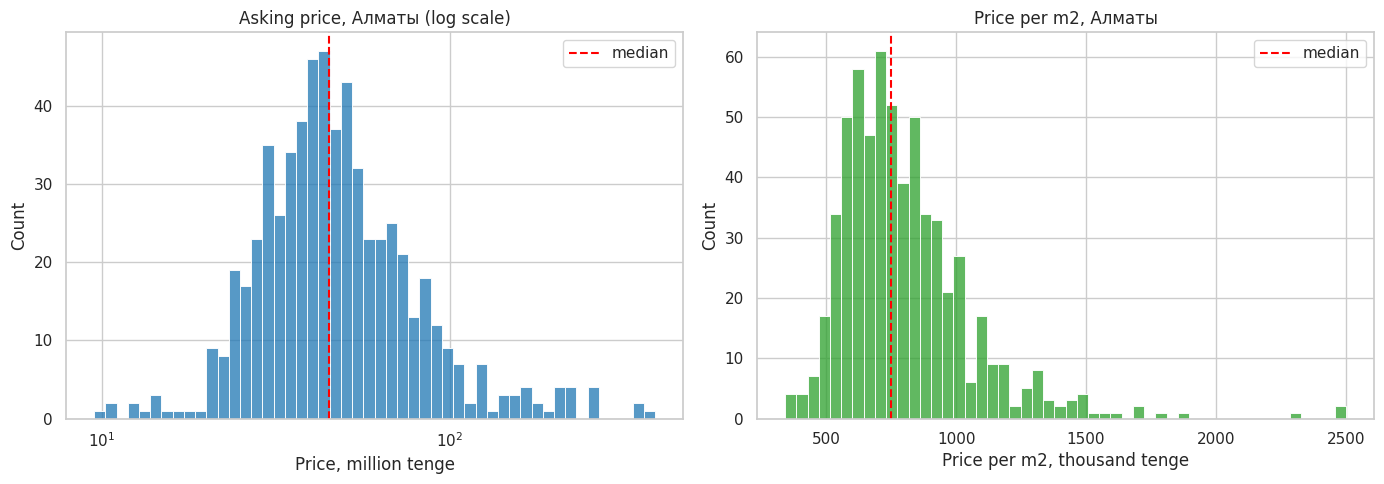

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(city_df["price"] / 1e6, bins=50, log_scale=True, color="tab:blue", ax=axes[0])
axes[0].axvline(city_df["price"].median() / 1e6, color="red", linestyle="--", label="median")
axes[0].set_title(f"Asking price, {CITY} (log scale)")
axes[0].set_xlabel("Price, million tenge")
axes[0].legend()

sns.histplot(city_df["price_per_m2"] / 1e3, bins=50, color="tab:green", ax=axes[1])
axes[1].axvline(city_df["price_per_m2"].median() / 1e3, color="red", linestyle="--", label="median")
axes[1].set_title(f"Price per m2, {CITY}")
axes[1].set_xlabel("Price per m2, thousand tenge")
axes[1].legend()

plt.tight_layout()
plt.savefig("images/price_distribution.png")
plt.show()

### 4.2 Price per m² by district

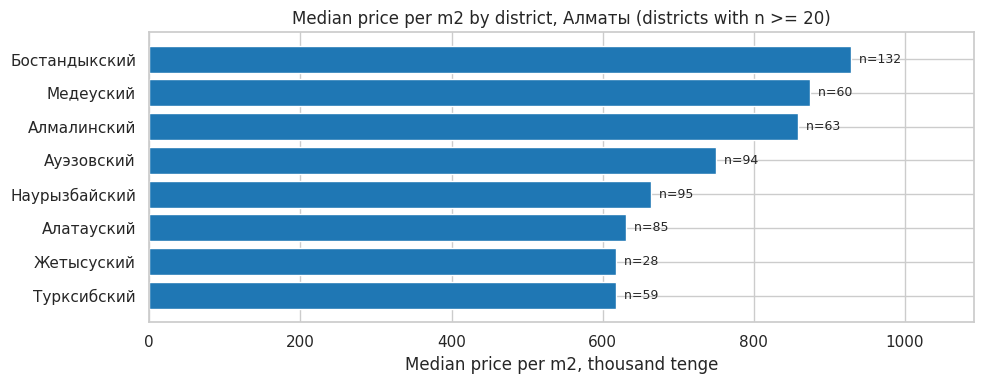

,n,median_price,median_ppm2
district,,,
Турксибский,59,33500000.0,618182.0
Жетысуский,28,35700000.0,618240.0
Алатауский,85,35500000.0,630952.0
Наурызбайский,95,37000000.0,664011.0
Ауэзовский,94,43000000.0,750000.0
Алмалинский,63,53500000.0,858333.0
Медеуский,60,64850000.0,874518.0
Бостандыкский,132,65000000.0,928016.0


In [29]:
dist = (city_df.dropna(subset=["district"])
        .groupby("district")
        .agg(n=("price", "size"), median_price=("price", "median"), median_ppm2=("price_per_m2", "median"))
        .query("n >= @MIN_N")
        .sort_values("median_ppm2"))

if dist.empty:
    print(f"No district has at least {MIN_N} listings. Scrape more pages or lower MIN_N.")
else:
    fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(dist))))
    bars = ax.barh(dist.index, dist["median_ppm2"] / 1e3, color="tab:blue")
    for b, n in zip(bars, dist["n"]):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  n={n}", va="center", fontsize=9)
    ax.set_title(f"Median price per m2 by district, {CITY} (districts with n >= {MIN_N})")
    ax.set_xlabel("Median price per m2, thousand tenge")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
    plt.tight_layout()
    plt.savefig("images/districts.png")
    plt.show()
dist.round(0)

### 4.3 Price vs area

Both axes are on a log scale. Spearman correlation is used because it does not assume a straight-line relationship and is robust to outliers.

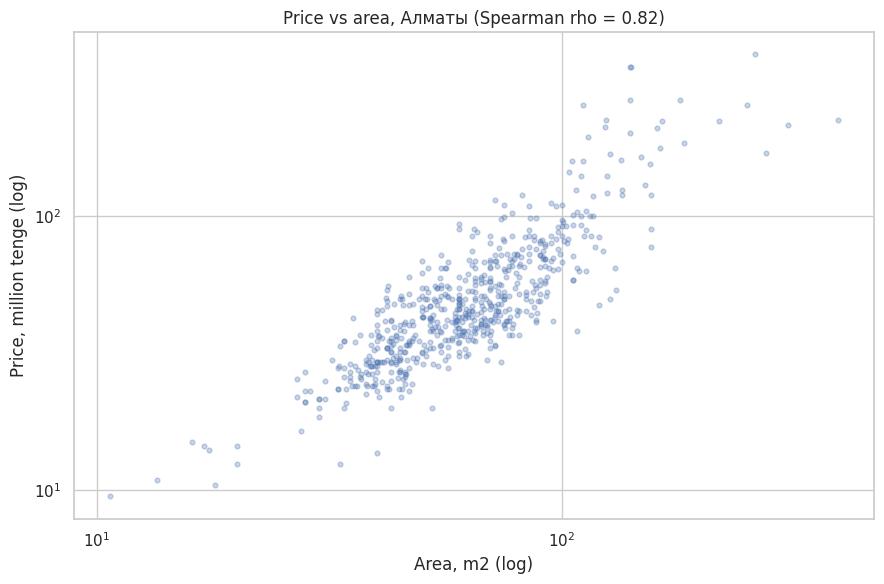

Spearman correlation between area and price: 0.82 (p = 9.3e-149)


In [30]:
rho, p = stats.spearmanr(city_df["area"], city_df["price"])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(city_df["area"], city_df["price"] / 1e6, alpha=0.3, s=12)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title(f"Price vs area, {CITY} (Spearman rho = {rho:.2f})")
ax.set_xlabel("Area, m2 (log)")
ax.set_ylabel("Price, million tenge (log)")
plt.tight_layout()
plt.savefig("images/price_vs_area.png")
plt.show()
print(f"Spearman correlation between area and price: {rho:.2f} (p = {p:.1e})")

### 4.4 Rooms, building type and year of construction

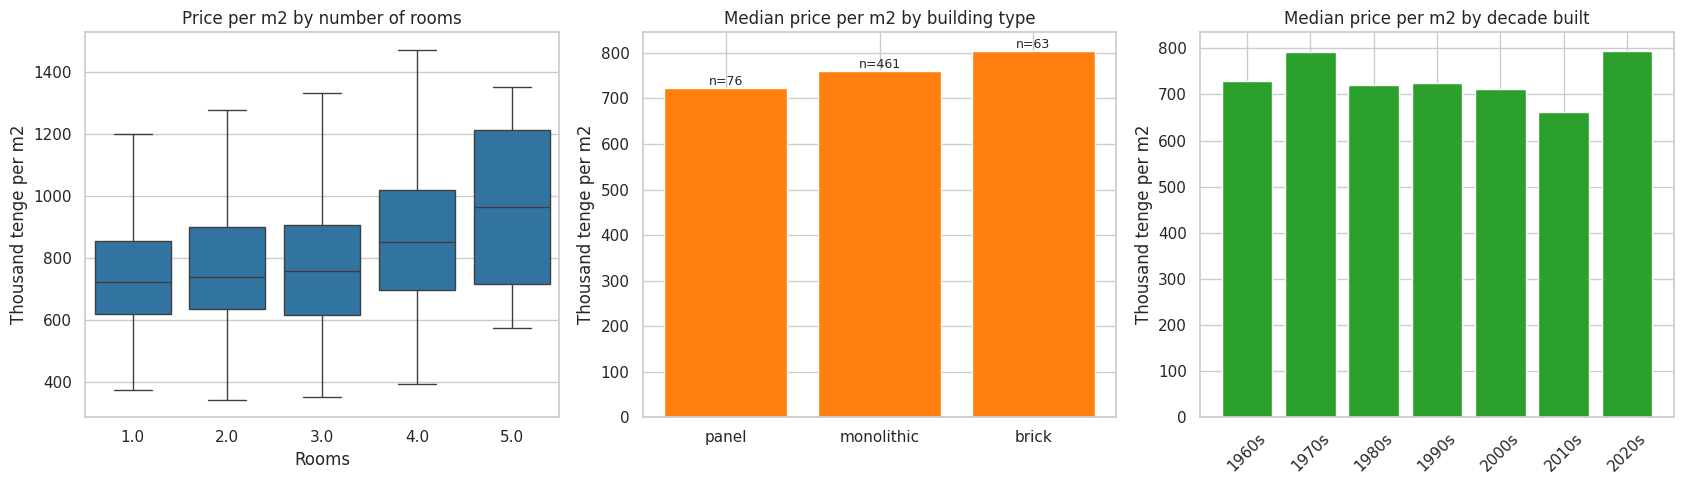

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

rooms_df = city_df[city_df["rooms"].between(1, 5)]
if len(rooms_df):
    sns.boxplot(data=rooms_df, x="rooms", y=rooms_df["price_per_m2"] / 1e3, showfliers=False, color="tab:blue", ax=axes[0])
axes[0].set_title("Price per m2 by number of rooms")
axes[0].set_xlabel("Rooms"); axes[0].set_ylabel("Thousand tenge per m2")

bt = (city_df.dropna(subset=["building_type"]).groupby("building_type")
      .agg(n=("price", "size"), med=("price_per_m2", "median")).query("n >= 10").sort_values("med"))
axes[1].bar(bt.index, bt["med"] / 1e3, color="tab:orange")
for i, (_, r) in enumerate(bt.iterrows()):
    axes[1].text(i, r["med"] / 1e3, f"n={int(r['n'])}", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Median price per m2 by building type")
axes[1].set_ylabel("Thousand tenge per m2")

yr = city_df.dropna(subset=["year_built"]).copy()
yr["decade"] = (yr["year_built"] // 10 * 10).astype(int)
yd = yr.groupby("decade").agg(n=("price", "size"), med=("price_per_m2", "median")).query("n >= 10")
axes[2].bar(yd.index.astype(str) + "s", yd["med"] / 1e3, color="tab:green")
axes[2].set_title("Median price per m2 by decade built")
axes[2].set_ylabel("Thousand tenge per m2")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("images/rooms_building_year.png")
plt.show()

### 4.5 Does the floor matter? A statistical test

Common belief: first and last floors are cheaper. Here it is tested on price per m² with the **Mann-Whitney U test** (no normality assumption) and a **bootstrap 95% confidence interval** for the difference in medians.

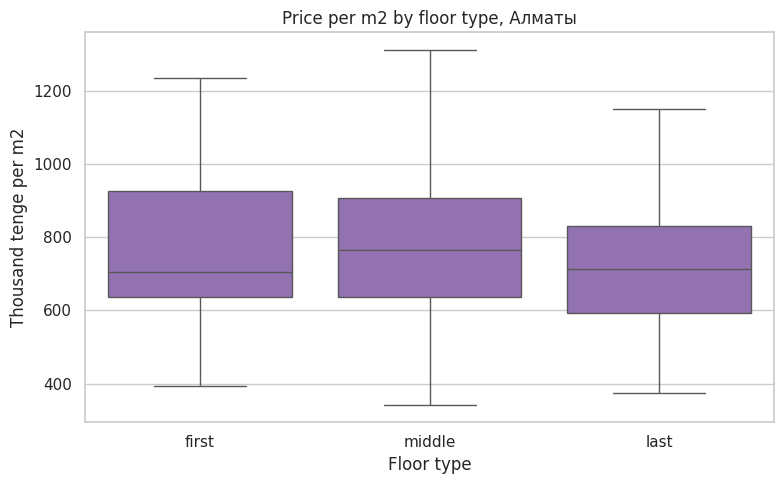

,comparison,n_a,n_b,median_diff_%,95% CI low,95% CI high,p_value
0,first vs middle floors,82,434,-7.6,-12.5,5.2,0.424223
1,last vs middle floors,88,434,-6.5,-16.4,0.5,0.019303


In [32]:
def compare_groups(a, b, label):
    a, b = a.dropna().values, b.dropna().values
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rng = np.random.default_rng(RANDOM_STATE)
    boots = [np.median(rng.choice(a, len(a))) / np.median(rng.choice(b, len(b))) - 1 for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5]) * 100
    return {"comparison": label, "n_a": len(a), "n_b": len(b),
            "median_diff_%": round((np.median(a) / np.median(b) - 1) * 100, 1),
            "95% CI low": round(lo, 1), "95% CI high": round(hi, 1), "p_value": p}

fl = city_df.dropna(subset=["floor_cat"])
floor_tests = pd.DataFrame()
if fl["floor_cat"].nunique() == 3 and fl["floor_cat"].value_counts().min() >= 10:
    mid = fl.loc[fl["floor_cat"] == "middle", "price_per_m2"]
    floor_tests = pd.DataFrame([
        compare_groups(fl.loc[fl["floor_cat"] == "first", "price_per_m2"], mid, "first vs middle floors"),
        compare_groups(fl.loc[fl["floor_cat"] == "last", "price_per_m2"], mid, "last vs middle floors"),
    ])
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(data=fl, x="floor_cat", y=fl["price_per_m2"] / 1e3, order=["first", "middle", "last"],
                showfliers=False, color="tab:purple", ax=ax)
    ax.set_title(f"Price per m2 by floor type, {CITY}")
    ax.set_xlabel("Floor type"); ax.set_ylabel("Thousand tenge per m2")
    plt.tight_layout()
    plt.savefig("images/floor_effect.png")
    plt.show()
else:
    print("Not enough listings with known floor and building height for this test.")
floor_tests

### 4.6 Suspicious listings

Listings whose price per m² is far from the median of their district may be data errors, typos in the ad, or genuinely special properties. They are flagged for manual review, not removed.

In [33]:
if not dist.empty:
    tmp = city_df.merge(dist[["median_ppm2"]].rename(columns={"median_ppm2": "district_median"}),
                        left_on="district", right_index=True)
    tmp["ratio_to_district_median"] = tmp["price_per_m2"] / tmp["district_median"]
    cols = ["Title", "district", "price", "area", "price_per_m2", "ratio_to_district_median", "Link"]
    cols = [c for c in cols if c in tmp.columns]
    print("Most underpriced vs district median:")
    display(tmp.nsmallest(5, "ratio_to_district_median")[cols].round(2))
    print("Most overpriced vs district median:")
    display(tmp.nlargest(5, "ratio_to_district_median")[cols].round(2))

Most underpriced vs district median:


,Title,district,price,area,price_per_m2,ratio_to_district_median,Link
471,1-комнатная квартира · 52.6 м² · 10/15 этаж,Алмалинский,20000000.0,52.6,380228.14,0.44,/a/show/1017130070
708,4-комнатная квартира · 127 м² · 1/4 этаж,Ауэзовский,50000000.0,127.0,393700.79,0.52,/a/show/1002031571
978,3-комнатная квартира · 108 м² · 10/16 этаж,Наурызбайский,38000000.0,108.0,351851.85,0.53,/a/show/671411813
350,3-комнатная квартира · 72 м² · 2/3 этаж,Алмалинский,34000000.0,72.0,472222.22,0.55,/a/show/1017411999
250,2-комнатная квартира · 40 м² · 2/3 этаж,Турксибский,13700000.0,40.0,342500.00,0.55,/a/show/1012060711


Most overpriced vs district median:


,Title,district,price,area,price_per_m2,ratio_to_district_median,Link
244,3-комнатная квартира · 140 м² · 8/9 этаж,Бостандыкский,350000000.0,140.00,2500000.00,2.69,/a/show/1017349145
807,3-комнатная квартира · 141.11 м² · 3/3 этаж,Бостандыкский,351100000.0,141.11,2488129.83,2.68,/a/show/1013425664
60,4-комнатная квартира · 111.3 м² · 14/33 этаж,Бостандыкский,255000000.0,111.30,2291105.12,2.47,/a/show/1017183188
192,4-комнатная квартира · 140 м² · 5/5 этаж,Медеуский,265000000.0,140.00,1892857.14,2.16,/a/show/1014981530
224,2-комнатная квартира · 103.56 м² · 3/3 этаж,Наурызбайский,145000000.0,103.56,1400154.50,2.11,/a/show/1013393435


## 5. Predicting price with machine learning

Target: **log of the asking price** (reduces the effect of expensive outliers). Features: area, rooms, floor, building height, year built, district, building type, floor type. Missing values are imputed inside the pipeline, so no information leaks from the test set. Models are compared with a naive baseline (always predict the median price).

Error metrics are shown in tenge: **MAE** (mean absolute error) and **MedAPE** (median absolute percentage error).

In [34]:
num_cols = [c for c in ["area", "rooms", "floor", "floors_total", "year_built"] if city_df[c].notna().sum() > 0]
cat_cols = [c for c in ["district", "building_type", "floor_cat"] if city_df[c].notna().sum() > 0]
model_df = city_df.copy()
for c in cat_cols:
    model_df[c] = model_df[c].astype(object).where(model_df[c].notna(), np.nan)

results, fitted = [], {}
if len(model_df) < 100:
    print("Fewer than 100 listings: modelling skipped. Scrape more pages.")
else:
    X = model_df[num_cols + cat_cols]
    y = np.log(model_df["price"])
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])
    models = {
        "Baseline (median)": DummyRegressor(strategy="median"),
        "Ridge regression": Ridge(alpha=1.0),
        "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    }
    price_test = np.exp(y_test.values)
    for name, est in models.items():
        pipe = Pipeline([("pre", pre), ("model", est)]).fit(X_train, y_train)
        pred = np.exp(pipe.predict(X_test))
        results.append({
            "model": name,
            "MAE, M tenge": mean_absolute_error(price_test, pred) / 1e6,
            "MedAPE, %": np.median(np.abs(pred - price_test) / price_test) * 100,
            "R2 (log price)": r2_score(y_test, np.log(pred)),
        })
        fitted[name] = (pipe, pred)
    results = pd.DataFrame(results).round(2).set_index("model")
results

,"MAE, M tenge","MedAPE, %",R2 (log price)
model,,,
Baseline (median),25.87,30.00,-0.01
Ridge regression,14.32,14.22,0.76
Random forest,13.04,10.77,0.80


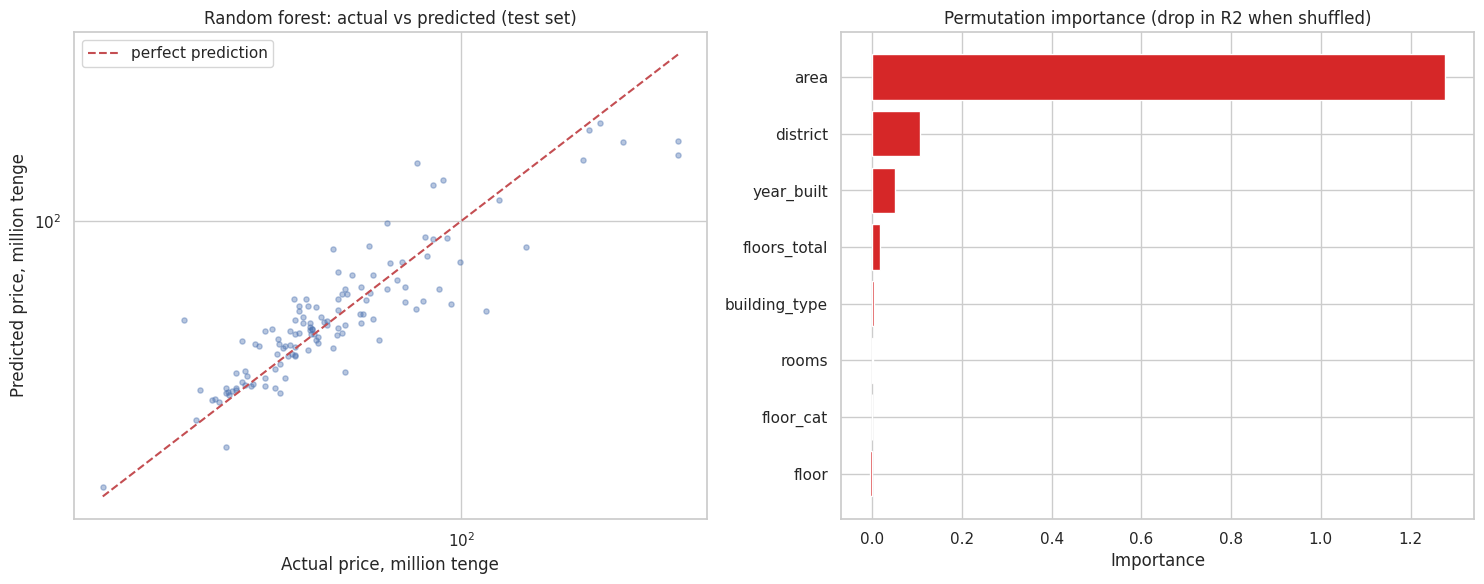

Best model: Random forest


In [35]:
if len(results):
    best = results.drop(index="Baseline (median)")["MedAPE, %"].idxmin()
    pipe, pred = fitted[best]

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    axes[0].scatter(price_test / 1e6, pred / 1e6, alpha=0.4, s=14)
    lim = [min(price_test.min(), pred.min()) / 1e6, max(price_test.max(), pred.max()) / 1e6]
    axes[0].plot(lim, lim, "r--", label="perfect prediction")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel("Actual price, million tenge"); axes[0].set_ylabel("Predicted price, million tenge")
    axes[0].set_title(f"{best}: actual vs predicted (test set)")
    axes[0].legend()

    perm = permutation_importance(pipe, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
    axes[1].barh(imp.index, imp.values, color="tab:red")
    axes[1].set_title("Permutation importance (drop in R2 when shuffled)")
    axes[1].set_xlabel("Importance")

    plt.tight_layout()
    plt.savefig("images/model.png")
    plt.show()
    print(f"Best model: {best}")

In [36]:
# Cross-validation: every listing is used for testing exactly once (more reliable than one 20% split)
from sklearn.model_selection import KFold, cross_val_predict

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
true_price = np.exp(y.values)
rows = []
for name, est in models.items():
    p = np.exp(cross_val_predict(Pipeline([("pre", pre), ("model", est)]), X, y, cv=kf))
    rows.append({
        "model": name,
        "MAE, M tenge": mean_absolute_error(true_price, p) / 1e6,
        "MedAPE, %": np.median(np.abs(p - true_price) / true_price) * 100,
        "R2 (log price)": r2_score(y, np.log(p)),
    })
pd.DataFrame(rows).round(2).set_index("model")

,"MAE, M tenge","MedAPE, %",R2 (log price)
model,,,
Baseline (median),23.33,30.76,-0.01
Ridge regression,13.17,13.07,0.78
Random forest,11.03,12.54,0.82


## 6. Findings (generated from the data)

In [37]:
lines = []
lines.append(f"- **Data:** {len(df):,} cleaned listings from {df['city'].nunique()} cities; analysed city: **{CITY}** ({len(city_df):,} listings, snapshot from {raw['ScrapedAt'].iloc[0] if 'ScrapedAt' in raw.columns else 'n/a'}).")
lines.append(f"- **Typical listing in {CITY}:** median asking price {city_df['price'].median()/1e6:.1f} M tenge, median area {city_df['area'].median():.0f} m2, median price per m2 {city_df['price_per_m2'].median():,.0f} tenge.")
if len(dist) >= 2:
    hi, lo = dist.iloc[-1], dist.iloc[0]
    lines.append(f"- **Districts:** the most expensive district by median price per m2 is **{dist.index[-1]}** ({hi.median_ppm2:,.0f} tenge, n={int(hi.n)}), the cheapest is **{dist.index[0]}** ({lo.median_ppm2:,.0f} tenge, n={int(lo.n)}): a {hi.median_ppm2/lo.median_ppm2:.1f}x difference.")
lines.append(f"- **Size:** Spearman correlation between area and price is {rho:.2f}.")
if len(floor_tests):
    for _, r in floor_tests.iterrows():
        verdict = "statistically significant" if r["p_value"] < 0.05 else "not statistically significant"
        lines.append(f"- **Floor ({r['comparison']}):** median price per m2 differs by {r['median_diff_%']:+.1f}% (95% CI {r['95% CI low']:+.1f}% to {r['95% CI high']:+.1f}%, p = {r['p_value']:.3f}), {verdict}.")
if len(results):
    b = results.loc[best]
    base = results.loc["Baseline (median)"]
    lines.append(f"- **Model:** {best} predicts the asking price with a median error of {b['MedAPE, %']:.0f}% (baseline: {base['MedAPE, %']:.0f}%), MAE {b['MAE, M tenge']:.1f} M tenge, R2 on log price {b['R2 (log price)']:.2f}.")
display(Markdown("\n".join(lines)))

- **Data:** 1,401 cleaned listings from 4 cities; analysed city: **Алматы** (616 listings, snapshot from 2026-11-19).
- **Typical listing in Алматы:** median asking price 45.0 M tenge, median area 62 m2, median price per m2 750,000 tenge.
- **Districts:** the most expensive district by median price per m2 is **Бостандыкский** (928,016 tenge, n=132), the cheapest is **Турксибский** (618,182 tenge, n=59): a 1.5x difference.
- **Size:** Spearman correlation between area and price is 0.82.
- **Floor (first vs middle floors):** median price per m2 differs by -7.6% (95% CI -12.5% to +5.2%, p = 0.424), not statistically significant.
- **Floor (last vs middle floors):** median price per m2 differs by -6.5% (95% CI -16.4% to +0.5%, p = 0.019), statistically significant.
- **Model:** Random forest predicts the asking price with a median error of 11% (baseline: 30%), MAE 13.0 M tenge, R2 on log price 0.80.

### Export the charts for GitHub

In [38]:
import shutil
shutil.make_archive("images", "zip", "images")
try:
    from google.colab import files
    files.download("images.zip")
except ImportError:
    print("images.zip created in the working directory")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Limitations and next steps

**Limitations**
- Prices are **asking prices** from ads, not final transaction prices; real deals are usually lower.
- The data is a **single snapshot**, so it shows no price trends over time.
- The scraped pages are not a random sample of the whole market (sorting on the site affects which ads appear first).
- Some ads have missing or wrongly typed parameters; missing values are kept missing, which reduces the sample for floor and year analysis.
- Small districts have few listings, so their medians are uncertain (see `n` on the charts).

**Next steps**
- Scrape the data regularly (for example weekly) and study price dynamics over time.
- Add features: distance to the city centre or metro, complex name, condition of the flat.
- Try gradient boosting and cross-validation; add prediction intervals.
- Extend the analysis to houses and commercial property and compare cities.